# Practical 5: Gradient Descent – Effect of Learning Rate

**Aim:** To analyze the effect of different learning rates on the convergence of Gradient Descent using a regression dataset.

**Dataset:** Advertising Sales Dataset (Kaggle)

**Kaggle link:** https://www.kaggle.com/datasets/yasserh/advertising-sales-dataset

### Dataset setup
1. Download the dataset from Kaggle.
2. Extract the ZIP file.
3. Keep `Advertising.csv` in the same folder as this notebook.
4. Run the cells one by one using Shift + Enter.

**X:** TV advertising  
**y:** Sales

This notebook follows your uploaded `exp5.ipynb` directly: NumPy arrays, `m = 0`, `b = 0`, `alpha`, `epochs`, `y_pred`, `dm`, `db`, parameter updates and Matplotlib plots. Only the sample X and y values are replaced with Kaggle data.

## 1. Import libraries

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the dataset

In [9]:
df = pd.read_csv("Advertising.csv")
df = df.rename(columns={"TV Ad Budget ($)": "TV", "Sales ($)": "Sales"})
df.head()

,Unnamed: 0,TV,Radio Ad Budget ($),Newspaper Ad Budget ($),Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## 3. Separate X and y

In [10]:
X = df["TV"].values
y = df["Sales"].values

# Scale X to make Gradient Descent stable
X = (X - np.mean(X)) / np.std(X)

n = len(X)
print("Number of rows:", n)

Number of rows: 200


## 4. Gradient Descent with different learning rates

In [11]:
learning_rates = [0.001, 0.01, 0.1]
epochs = 1000

for alpha in learning_rates:

    m = 0
    b = 0
    loss = []

    for i in range(epochs):

        y_pred = m * X + b

        dm = (-2/n) * np.sum(X * (y - y_pred))
        db = (-2/n) * np.sum(y - y_pred)

        m = m - alpha * dm
        b = b - alpha * db

        error = np.mean((y - y_pred) ** 2)
        loss.append(error)

    print("Learning Rate:", alpha)
    print("Slope:", m)
    print("Intercept:", b)
    print("Final Error:", loss[-1])
    print()

Learning Rate: 0.001
Slope: 3.5211576230840698
Intercept: 12.128557733991382
Final Error: 14.41760779259077

Learning Rate: 0.01
Slope: 4.071006113795372
Intercept: 14.022499976400585
Final Error: 10.512652915656759

Learning Rate: 0.1
Slope: 4.071006120646741
Intercept: 14.022499999999996
Final Error: 10.512652915656759



## 5. Plot convergence graph

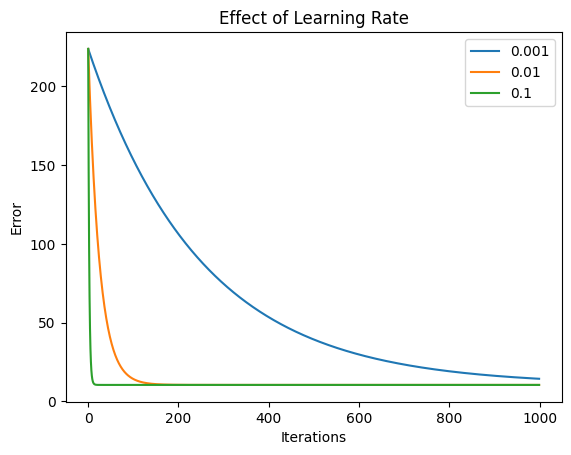

In [12]:
for alpha in learning_rates:

    m = 0
    b = 0
    loss = []

    for i in range(epochs):

        y_pred = m * X + b

        dm = (-2/n) * np.sum(X * (y - y_pred))
        db = (-2/n) * np.sum(y - y_pred)

        m = m - alpha * dm
        b = b - alpha * db

        error = np.mean((y - y_pred) ** 2)
        loss.append(error)

    plt.plot(loss, label=alpha)

plt.xlabel("Iterations")
plt.ylabel("Error")
plt.title("Effect of Learning Rate")
plt.legend()
plt.show()

## 6. Conclusion

Thus, Gradient Descent was implemented on the Kaggle Advertising dataset using different learning rates. The graph shows the effect of learning rate on error reduction. A small learning rate takes more iterations, while a suitable higher learning rate converges faster.

## Quick revision

| Code | Meaning |
|---|---|
| `m = 0`, `b = 0` | Initial values |
| `alpha` | Learning rate |
| `epochs` | Number of iterations |
| `y_pred = m * X + b` | Prediction |
| `dm` | Gradient of slope |
| `db` | Gradient of intercept |
| `m = m - alpha * dm` | Update slope |
| `b = b - alpha * db` | Update intercept |
| `np.mean((y-y_pred)**2)` | Calculate error |
| `plt.plot()` | Plot convergence |

**Note:** The Gradient Descent formula and code pattern are the same as your uploaded `exp5.ipynb`. X is standardized before training so the three learning rates can be compared without the model diverging.